<a href="https://colab.research.google.com/github/HONGSAHUN/AI-Class/blob/main/Week08_1026/mobile_classification%26Regression_1026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Mobile Price — 가격 등급 분류 + 배터리 용량 회귀
- 데이터: GitHub `mobile.csv` — 2,000행, 21열 (모두 숫자)
- **Part 1 분류**: `price_range`(0~3, 4등급) 예측
- **Part 2 회귀**: `price_range` 열을 지운 뒤 `battery_power`(배터리 용량, mAh) 예측

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, f1_score, confusion_matrix, classification_report,
                             mean_absolute_error, mean_squared_error, r2_score)
import warnings
warnings.filterwarnings('ignore')

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/mobile.csv")
print(df.shape)
df.head()

(2000, 21)


,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,...,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi,price_range
0,842,0,2.2,0,1,0,7,0.6,188,2,...,20,756,2549,9,7,19,0,0,1,1
1,1021,1,0.5,1,0,1,53,0.7,136,3,...,905,1988,2631,17,3,7,1,1,0,2
2,563,1,0.5,1,2,1,41,0.9,145,5,...,1263,1716,2603,11,2,9,1,1,0,2
3,615,1,2.5,0,0,0,10,0.8,131,6,...,1216,1786,2769,16,8,11,1,0,0,2
4,1821,1,1.2,0,13,1,44,0.6,141,2,...,1208,1212,1411,8,2,15,1,1,0,1


In [4]:
df.isnull().sum().sum()

np.int64(0)

In [5]:
df['price_range'].value_counts()   # 500개씩 완전 균형

,count
price_range,
1,500
2,500
3,500
0,500


---
# Part 1. 분류 — price_range (4등급)

In [6]:
df.corr()['price_range'].sort_values(ascending=False)   # ram이 압도적으로 큼

,price_range
price_range,1.000000
ram,0.917046
battery_power,0.200723
px_width,0.165818
px_height,0.148858
int_memory,0.044435
sc_w,0.038711
pc,0.033599
three_g,0.023611
sc_h,0.022986


In [7]:
X = df.drop('price_range', axis=1)
y = df['price_range']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=0, stratify=y)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

X_train.shape, X_test.shape, y_train.shape, y_test.shape

((1600, 20), (400, 20), (1600,), (400,))

In [8]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "SVM": SVC(random_state=0),
    "Decision Tree": DecisionTreeClassifier(random_state=0),
    "Random Forest": RandomForestClassifier(random_state=0),
    "KNN": KNeighborsClassifier(),
    "MLP": MLPClassifier(max_iter=1000, random_state=0),
}

results = []
for name, clf in models.items():
    clf.fit(X_train, y_train)
    pred = clf.predict(X_test)
    acc = accuracy_score(y_test, pred)
    f1 = f1_score(y_test, pred, average='macro')
    results.append([name, acc, f1])

    print(f"\n--- {name} ---")
    print("Accuracy:", round(acc, 4), " Macro F1:", round(f1, 4))
    print(confusion_matrix(y_test, pred))

result_df = pd.DataFrame(results, columns=['model', 'accuracy', 'macro_f1'])
result_df = result_df.sort_values('macro_f1', ascending=False).reset_index(drop=True)
result_df


--- Logistic Regression ---
Accuracy: 0.955  Macro F1: 0.9551
[[96  4  0  0]
 [ 5 93  2  0]
 [ 0  4 95  1]
 [ 0  0  2 98]]

--- SVM ---
Accuracy: 0.8925  Macro F1: 0.893
[[92  8  0  0]
 [ 7 85  8  0]
 [ 0  8 88  4]
 [ 0  0  8 92]]

--- Decision Tree ---
Accuracy: 0.8375  Macro F1: 0.8375
[[90 10  0  0]
 [ 8 84  8  0]
 [ 0 11 75 14]
 [ 0  0 14 86]]

--- Random Forest ---
Accuracy: 0.8875  Macro F1: 0.8877
[[93  7  0  0]
 [ 8 88  4  0]
 [ 0 14 81  5]
 [ 0  0  7 93]]

--- KNN ---
Accuracy: 0.4875  Macro F1: 0.4886
[[76 20  3  1]
 [39 36 21  4]
 [11 44 38  7]
 [ 2 14 39 45]]

--- MLP ---
Accuracy: 0.9225  Macro F1: 0.923
[[93  7  0  0]
 [ 4 91  5  0]
 [ 0  6 92  2]
 [ 0  0  7 93]]


,model,accuracy,macro_f1
0,Logistic Regression,0.9550,0.955074
1,MLP,0.9225,0.923032
2,SVM,0.8925,0.892979
3,Random Forest,0.8875,0.887656
4,Decision Tree,0.8375,0.837506
5,KNN,0.4875,0.488618


Best: Logistic Regression
              precision    recall  f1-score   support

           0       0.95      0.96      0.96       100
           1       0.92      0.93      0.93       100
           2       0.96      0.95      0.95       100
           3       0.99      0.98      0.98       100

    accuracy                           0.95       400
   macro avg       0.96      0.95      0.96       400
weighted avg       0.96      0.95      0.96       400



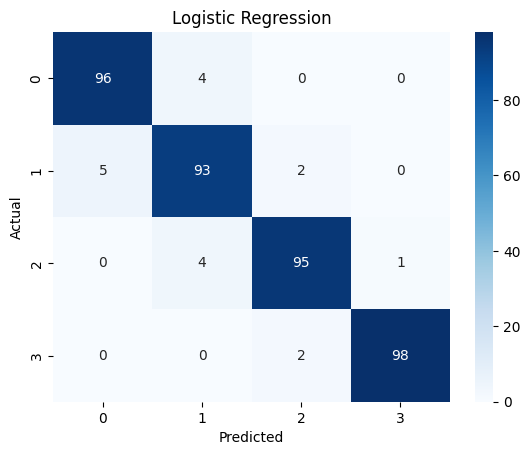

In [9]:
best_name = result_df.loc[0, 'model']
best_pred = models[best_name].predict(X_test)

print("Best:", best_name)
print(classification_report(y_test, best_pred))

cm = confusion_matrix(y_test, best_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.title(best_name)
plt.show()

---
# Part 2. 회귀 — price_range 지우고 battery_power 예측
1. `price_range` 열을 지움
2. 남은 열에서 `battery_power`를 정답 y로, 나머지를 입력 X로
3. 변수 이름 끝에 `_r`을 붙여 Part 1 변수와 섞이지 않게 함

In [10]:
df_reg = df.drop('price_range', axis=1)

X_r = df_reg.drop('battery_power', axis=1)
y_r = df_reg['battery_power']
print(X_r.shape, y_r.shape)

X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(
    X_r, y_r, test_size=0.2, random_state=0)

scaler_r = StandardScaler()
X_train_r = scaler_r.fit_transform(X_train_r)
X_test_r = scaler_r.transform(X_test_r)

X_train_r.shape, X_test_r.shape

(2000, 19) (2000,)


((1600, 19), (400, 19))

`DummyRegressor`는 아무 입력도 보지 않고 **학습 데이터의 평균만 답하는 기준선**. 다른 모델이 이것보다 나아야 의미가 있음.
- MAE·MSE·RMSE: 작을수록 좋음 (RMSE 단위 = mAh)
- R²: 1에 가까울수록 좋음, **0이면 평균 찍기와 같고, 음수면 그보다 못함**

In [11]:
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.neural_network import MLPRegressor

reg_models = {
    "Baseline (mean)": DummyRegressor(strategy='mean'),
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(random_state=0),
    "Random Forest": RandomForestRegressor(random_state=0),
    "KNN": KNeighborsRegressor(),
    "MLP": MLPRegressor(hidden_layer_sizes=(64, 32), max_iter=2000, random_state=0),
}

reg_results = []
for name, reg in reg_models.items():
    reg.fit(X_train_r, y_train_r)
    pred_r = reg.predict(X_test_r)
    mae = mean_absolute_error(y_test_r, pred_r)
    mse = mean_squared_error(y_test_r, pred_r)
    reg_results.append([name, mae, mse, mse ** 0.5, r2_score(y_test_r, pred_r)])

reg_df = pd.DataFrame(reg_results, columns=['model', 'MAE', 'MSE', 'RMSE', 'R2'])
reg_df.round(3)

,model,MAE,MSE,RMSE,R2
0,Baseline (mean),368.952,183804.843,428.725,-0.005
1,Linear Regression,371.733,185988.375,431.264,-0.017
2,Decision Tree,481.148,353782.802,594.796,-0.934
3,Random Forest,366.023,183979.010,428.928,-0.006
4,KNN,396.512,225945.369,475.337,-0.235
5,MLP,443.885,294798.229,542.953,-0.611


## 결과 해석 — 왜 회귀가 거의 안 맞나
battery_power와 다른 열의 상관계수를 보면, `price_range`(약 0.20)를 빼면 전부 0.05 이하.
→ 지운 `price_range`가 배터리 용량에 대한 **거의 유일한 정보**였음. 모델 문제가 아니라 데이터에 예측할 단서가 없음.

In [12]:
df.corr()['battery_power'].drop('battery_power').abs().sort_values(ascending=False).head(6)

,battery_power
price_range,0.200723
talk_time,0.052510
dual_sim,0.041847
m_dep,0.034085
fc,0.033334
pc,0.031441


In [13]:
# 비교: price_range를 지우지 않고 입력에 남겼다면?
X_k = df.drop('battery_power', axis=1)
X_train_k, X_test_k, y_train_k, y_test_k = train_test_split(X_k, y_r, test_size=0.2, random_state=0)
sc_k = StandardScaler()
X_train_k = sc_k.fit_transform(X_train_k)
X_test_k = sc_k.transform(X_test_k)

for name in ["Baseline (mean)", "Linear Regression", "Random Forest"]:
    reg = reg_models[name]
    reg.fit(X_train_k, y_train_k)
    pred_k = reg.predict(X_test_k)
    print(f"{name:18s} RMSE: {mean_squared_error(y_test_k, pred_k) ** 0.5:7.2f}   R2: {r2_score(y_test_k, pred_k):.3f}")

Baseline (mean)    RMSE:  428.72   R2: -0.005
Linear Regression  RMSE:  362.96   R2: 0.280
Random Forest      RMSE:  362.27   R2: 0.283


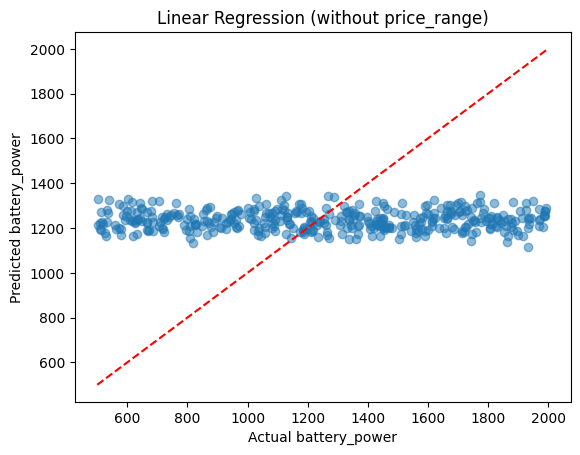

In [14]:
# 실제 vs 예측 (Linear Regression, price_range 지운 버전, 빨간 점선 : 예측값이 실제값인 선 y = x)
lr = LinearRegression().fit(X_train_r, y_train_r)
plt.scatter(y_test_r, lr.predict(X_test_r), alpha=0.5)
plt.plot([500, 2000], [500, 2000], 'r--')
plt.xlabel('Actual battery_power'); plt.ylabel('Predicted battery_power')
plt.title('Linear Regression (without price_range)')
plt.show()

## 결론 — 배터리 용량 회귀가 실패한 이유
- `price_range`를 지우면 남은 열과 `battery_power`의 상관계수가 모두 0.05 이하 → 입력에 배터리 용량에 대한 정보가 없음
- 그래서 모든 모델의 R²가 0 이하 = 평균값(약 1236 mAh)만 찍는 기준선과 같거나 더 나쁨. 복잡한 모델(Decision Tree, MLP)은 우연한 패턴을 외워 오히려 더 나빠짐(과대적합)
- `price_range`를 남기면 R² 0.28로 개선 → 지운 열이 거의 유일한 정보였음
- **모델은 데이터에 있는 관계를 찾을 뿐 없는 관계를 만들지 못한다. 성능의 한계는 모델이 아니라 데이터가 정한다.**